# Construction Materials Cost Planner - Analysis Notebook
**Student:** ahmed adel

This notebook explains the analysis behind the application. Run all cells from the project folder (`Kernel > Restart & Run All`). It uses the same functions as `main.py`.

## 1. Module 1 - required material quantities
For each concrete element:
- net volume = length x width x height
- gross volume = net volume x (1 + waste % / 100)
- cement = 300 kg/m3, sand = 0.5 m3/m3, aggregate = 0.8 m3/m3 of gross volume

In [13]:
import pandas as pd
from module1_calculator import ElementManager
from module2_analysis import *

manager = ElementManager()
manager.load_from_csv()
df_elements = pd.DataFrame(manager.list_elements())
df_elements

,element_id,element_name,site,length_m,width_m,height_m,waste_pct,net_volume_m3,gross_volume_m3,required_cement_kg,required_sand_m3,required_aggregate_m3
0,E01,Footing F1,Site A,2.5,2.50,0.60,5.0,3.750,3.9375,1181.25,1.97,3.15
1,E02,Column C1,Site A,0.4,0.40,3.00,4.0,0.480,0.4992,149.76,0.25,0.40
2,E03,Beam B1,Site A,6.0,0.30,0.50,5.0,0.900,0.9450,283.50,0.47,0.76
3,E04,Slab S1,Site A,8.0,5.00,0.15,6.0,6.000,6.3600,1908.00,3.18,5.09
4,E05,Footing F2,Site B,3.0,3.00,0.70,5.0,6.300,6.6150,1984.50,3.31,5.29
5,E06,Wall W1,Site B,10.0,0.25,3.00,7.0,7.500,8.0250,2407.50,4.01,6.42
6,E07,Slab S2,Site B,12.0,6.00,0.20,6.0,14.400,15.2640,4579.20,7.63,12.21
7,E08,Column C2,Site B,0.5,0.50,3.50,4.0,0.875,0.9100,273.00,0.46,0.73


In [14]:
import os
import shutil

# Ensure the expected /content/data directory exists and populate it
source_dir = '/content/content/data'
target_dir = '/content/data'

if os.path.exists(source_dir):
    os.makedirs(target_dir, exist_ok=True)
    for file_name in os.listdir(source_dir):
        shutil.copy(os.path.join(source_dir, file_name), os.path.join(target_dir, file_name))
    print("Data files successfully copied to /content/data/")
else:
    print("Source data folder not found at /content/content/data")

Data files successfully copied to /content/data/


In [15]:
# Totals per site
pd.DataFrame(manager.site_summary())

,site,element_count,net_volume_m3,gross_volume_m3,required_cement_kg,required_sand_m3,required_aggregate_m3
0,Site A,4,11.13,11.74,3522.51,5.87,9.39
1,Site B,4,29.08,30.81,9244.20,15.41,24.65


## 2. Module 2 - cleaning the data
Rules applied with pandas: prices must be > 0 and in the expected unit (cement kg, sand/aggregate m3); duplicate `transaction_id`s are dropped (first kept); missing or non-positive quantities, invalid dates, unknown element IDs and supplier/material pairs without a price are rejected. Every rejected record is listed with its reason.

In [16]:
df_merged, df_prices, df_rejected = load_and_clean_data(valid_element_ids=set(manager.elements))
print(len(df_merged), "valid purchase rows;", len(df_rejected), "rejected")
df_rejected

35 valid purchase rows; 5 rejected


,record_type,record_id,reason
0,purchase,T009,Duplicate transaction_id
1,purchase,T012,Missing quantity
2,purchase,T014,Missing quantity
3,purchase,T025,Duplicate transaction_id
4,purchase,T027,Missing quantity


## 3. Cost per site, supplier and month
cost = quantity x unit price, after merging purchases with prices on `supplier_id` + `material`, and with elements on `element_id` (to get the site).

In [17]:
calculate_costs_summary(df_merged, df_elements)

,site,supplier_id,month,cost
0,Site A,S01,2026-08,172.60
1,Site A,S01,2026-09,53.60
2,Site A,S02,2026-08,118.78
3,Site A,S02,2026-09,367.35
4,Site B,S01,2026-08,338.15
5,Site B,S01,2026-09,1103.65
6,Site B,S02,2026-08,70.32
7,Site B,S02,2026-09,95.90


## 4. Required vs purchased
Required quantities come from Module 1; purchased quantities are summed per element and material. Units are consistent (cement kg, sand/aggregate m3). Negative variance = **Shortage**, otherwise **Surplus**.

In [18]:
comp = compare_required_vs_purchased(df_elements, df_merged)
display(comp)
comp["status"].value_counts()

,element_id,site,required_qty,material,unit,purchased_qty,variance,status
0,E01,Site A,3.15,Aggregate,m3,3.35,0.20,Surplus
1,E01,Site A,1181.25,Cement,kg,1040.00,-141.25,Shortage
2,E01,Site A,1.97,Sand,m3,2.25,0.28,Surplus
3,E02,Site A,0.40,Aggregate,m3,0.25,-0.15,Shortage
4,E02,Site A,149.76,Cement,kg,70.00,-79.76,Shortage
5,E02,Site A,0.25,Sand,m3,0.25,0.00,Surplus
6,E03,Site A,0.76,Aggregate,m3,0.85,0.09,Surplus
7,E03,Site A,283.50,Cement,kg,290.00,6.50,Surplus
8,E03,Site A,0.47,Sand,m3,0.45,-0.02,Shortage
9,E04,Site A,5.09,Aggregate,m3,4.15,-0.94,Shortage


,count
status,
Surplus,12
Shortage,12


## 5. NumPy price sensitivity
Required totals and the **lowest** price per material are stored as NumPy arrays; total cost is their dot product. One material's price is then raised by a chosen percentage.

In [19]:
res = numpy_price_sensitivity_analysis(df_elements, df_prices, "Cement", 15)
res

{'material': 'Cement',
 'percentage': 15,
 'baseline_prices': {'Cement': 0.11, 'Sand': 14.5, 'Aggregate': 21.0},
 'required_totals': {'Cement': 12766.710000000001,
  'Sand': 21.28,
  'Aggregate': 34.05},
 'baseline_cost': 2427.9481,
 'inflated_cost': 2638.5988150000003,
 'cost_increase': 210.65071500000022}

In [20]:
# Effect of a +15% rise for each material
import pandas as pd
pd.DataFrame([numpy_price_sensitivity_analysis(df_elements, df_prices, m, 15) for m in MATERIALS])[
    ["material", "percentage", "baseline_cost", "inflated_cost", "cost_increase"]]

,material,percentage,baseline_cost,inflated_cost,cost_increase
0,Cement,15,2427.9481,2638.598815,210.650715
1,Sand,15,2427.9481,2474.232100,46.284000
2,Aggregate,15,2427.9481,2535.205600,107.257500


## 6. Charts
Four charts are saved as PNG files in `outputs/`: monthly spend (line), spend per supplier (bar), quantity vs cost per material (scatter), and distribution of transaction costs (histogram).

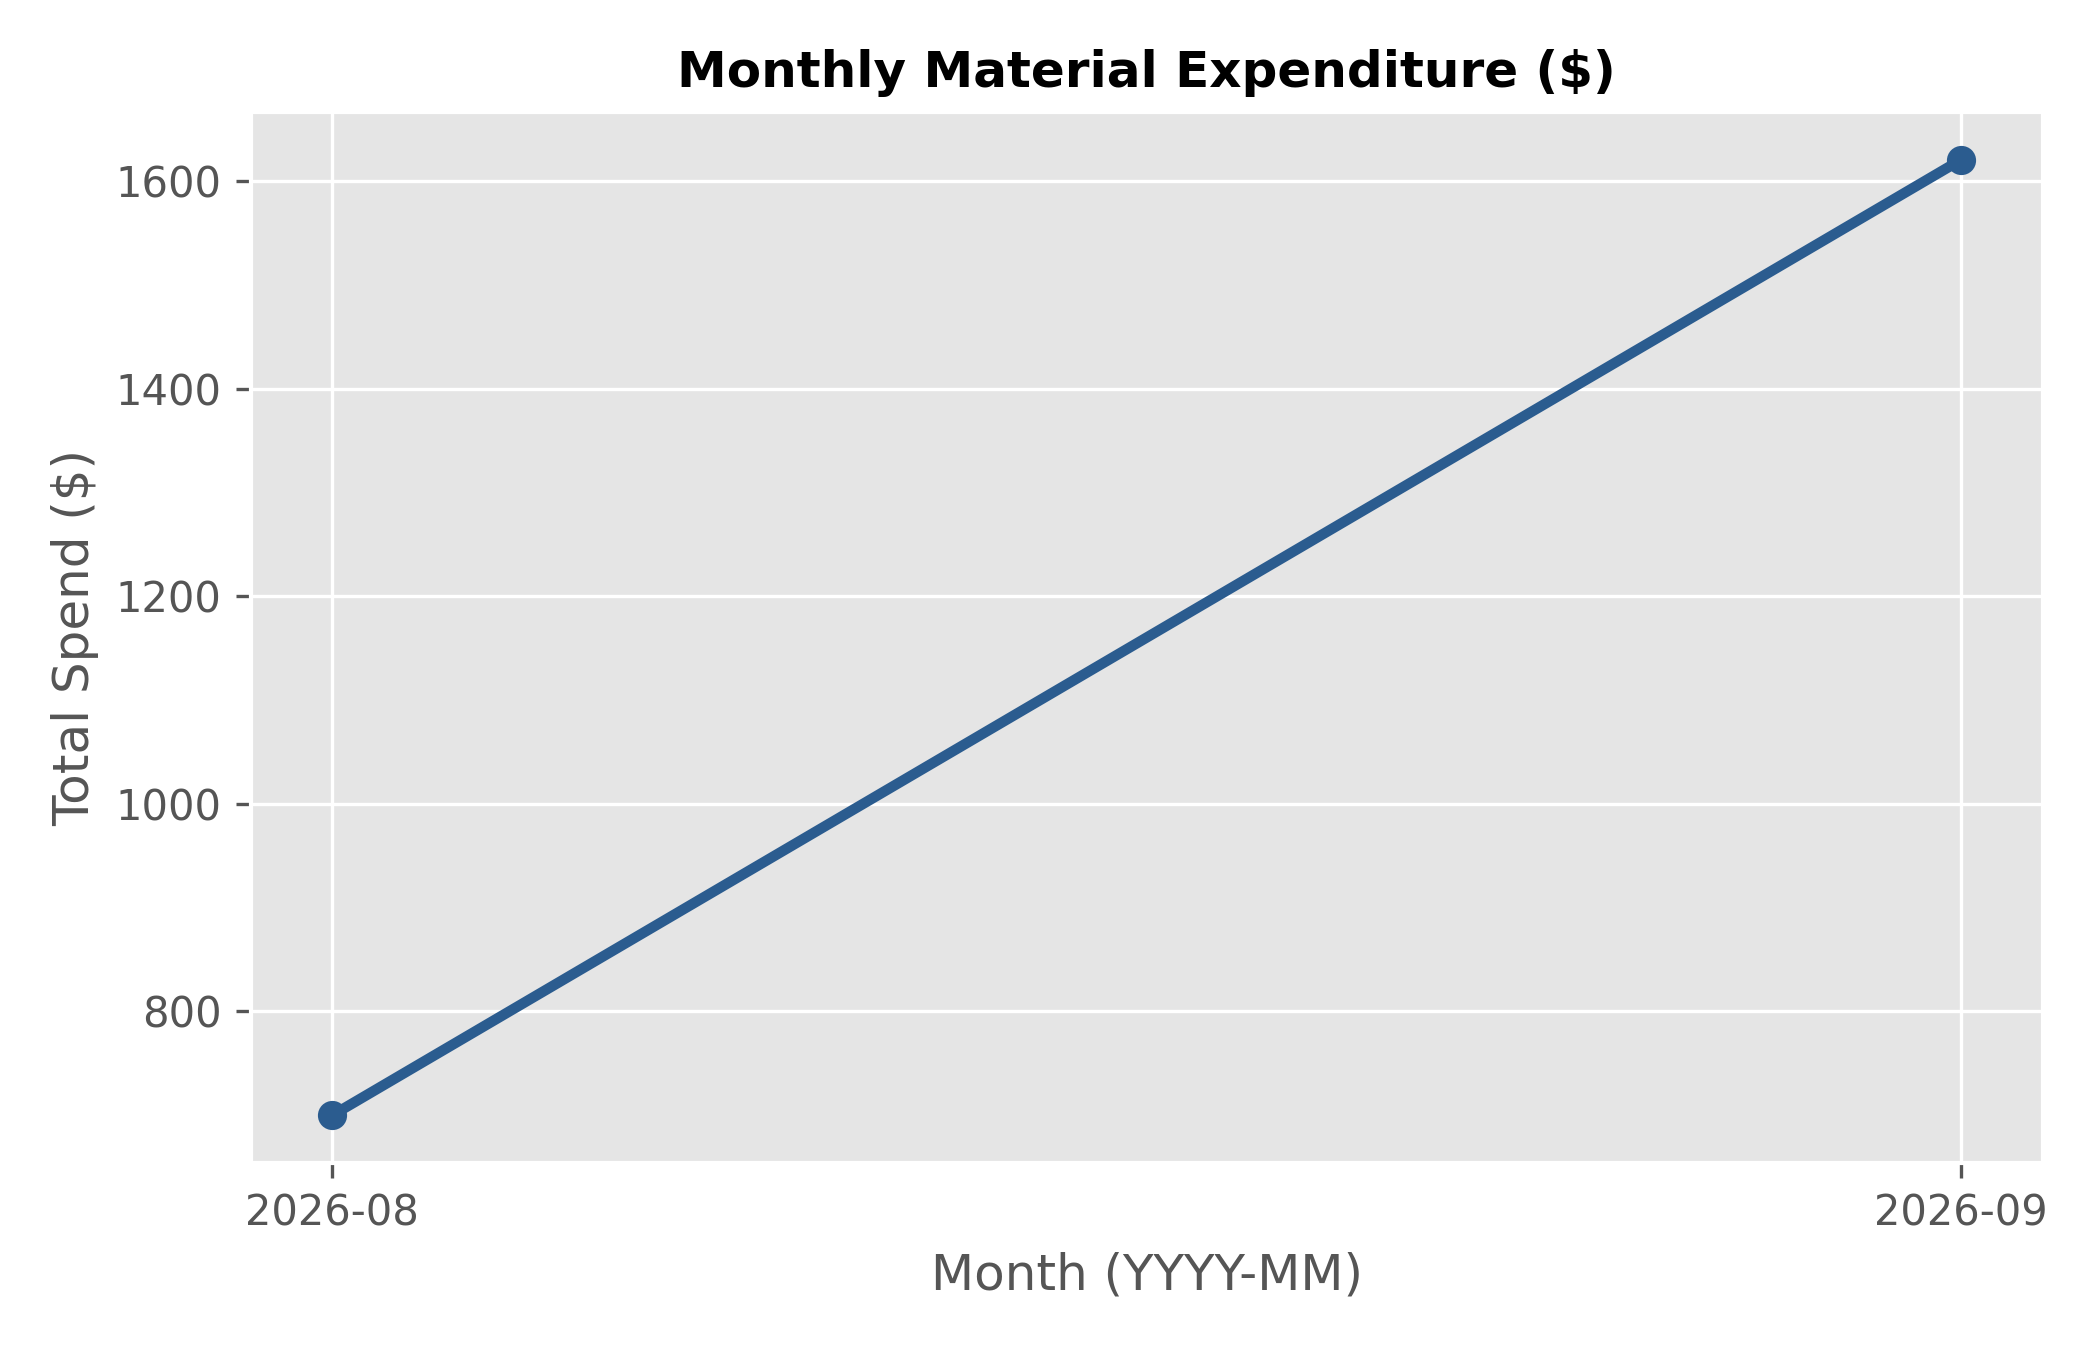

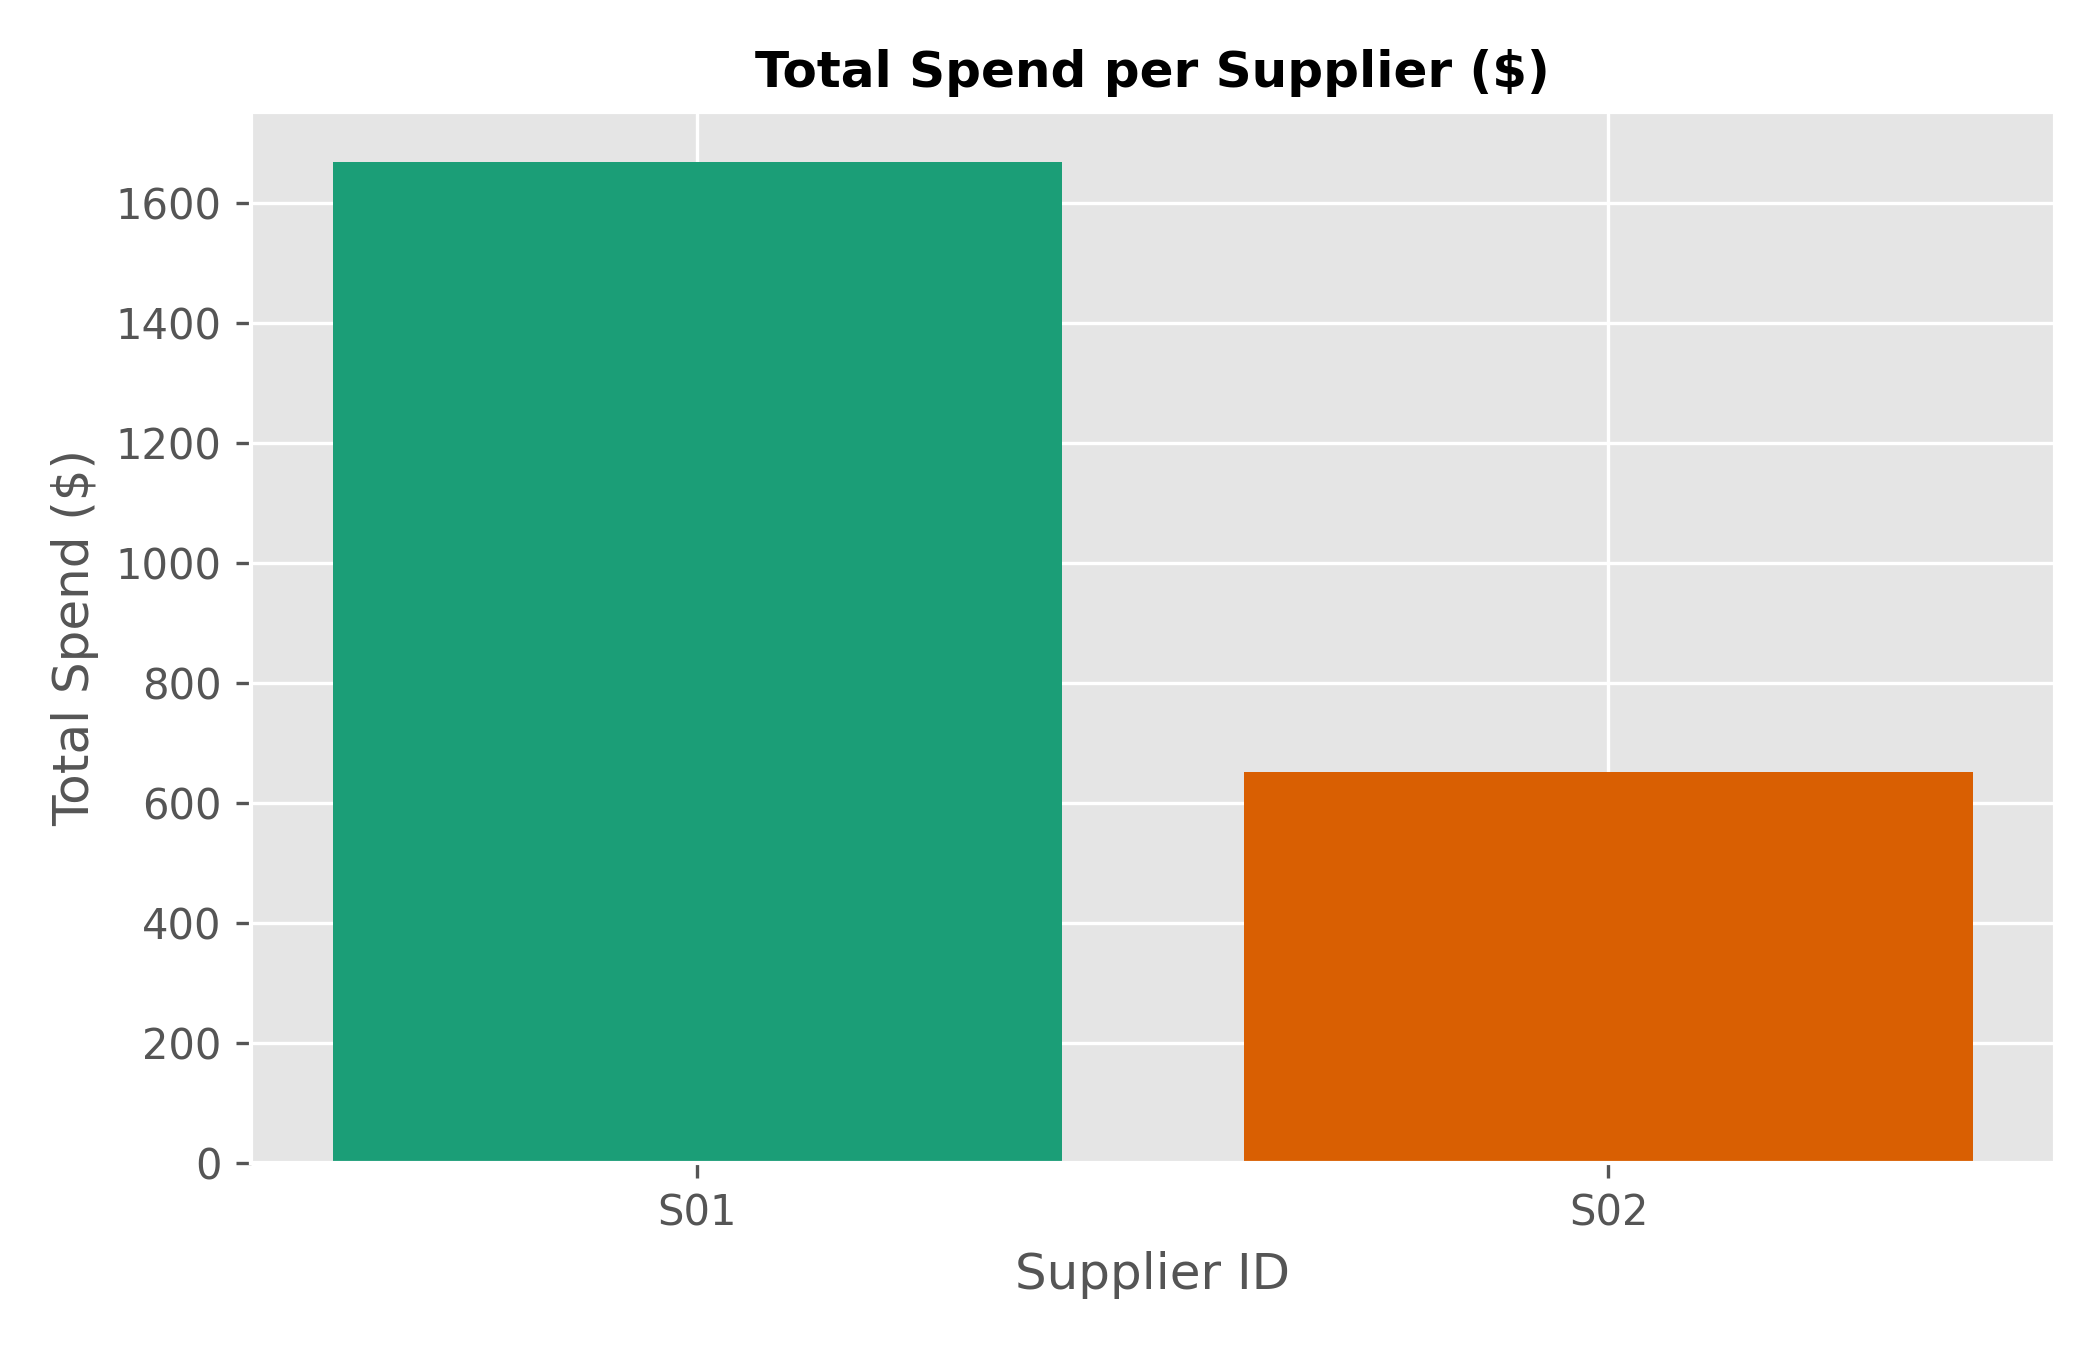

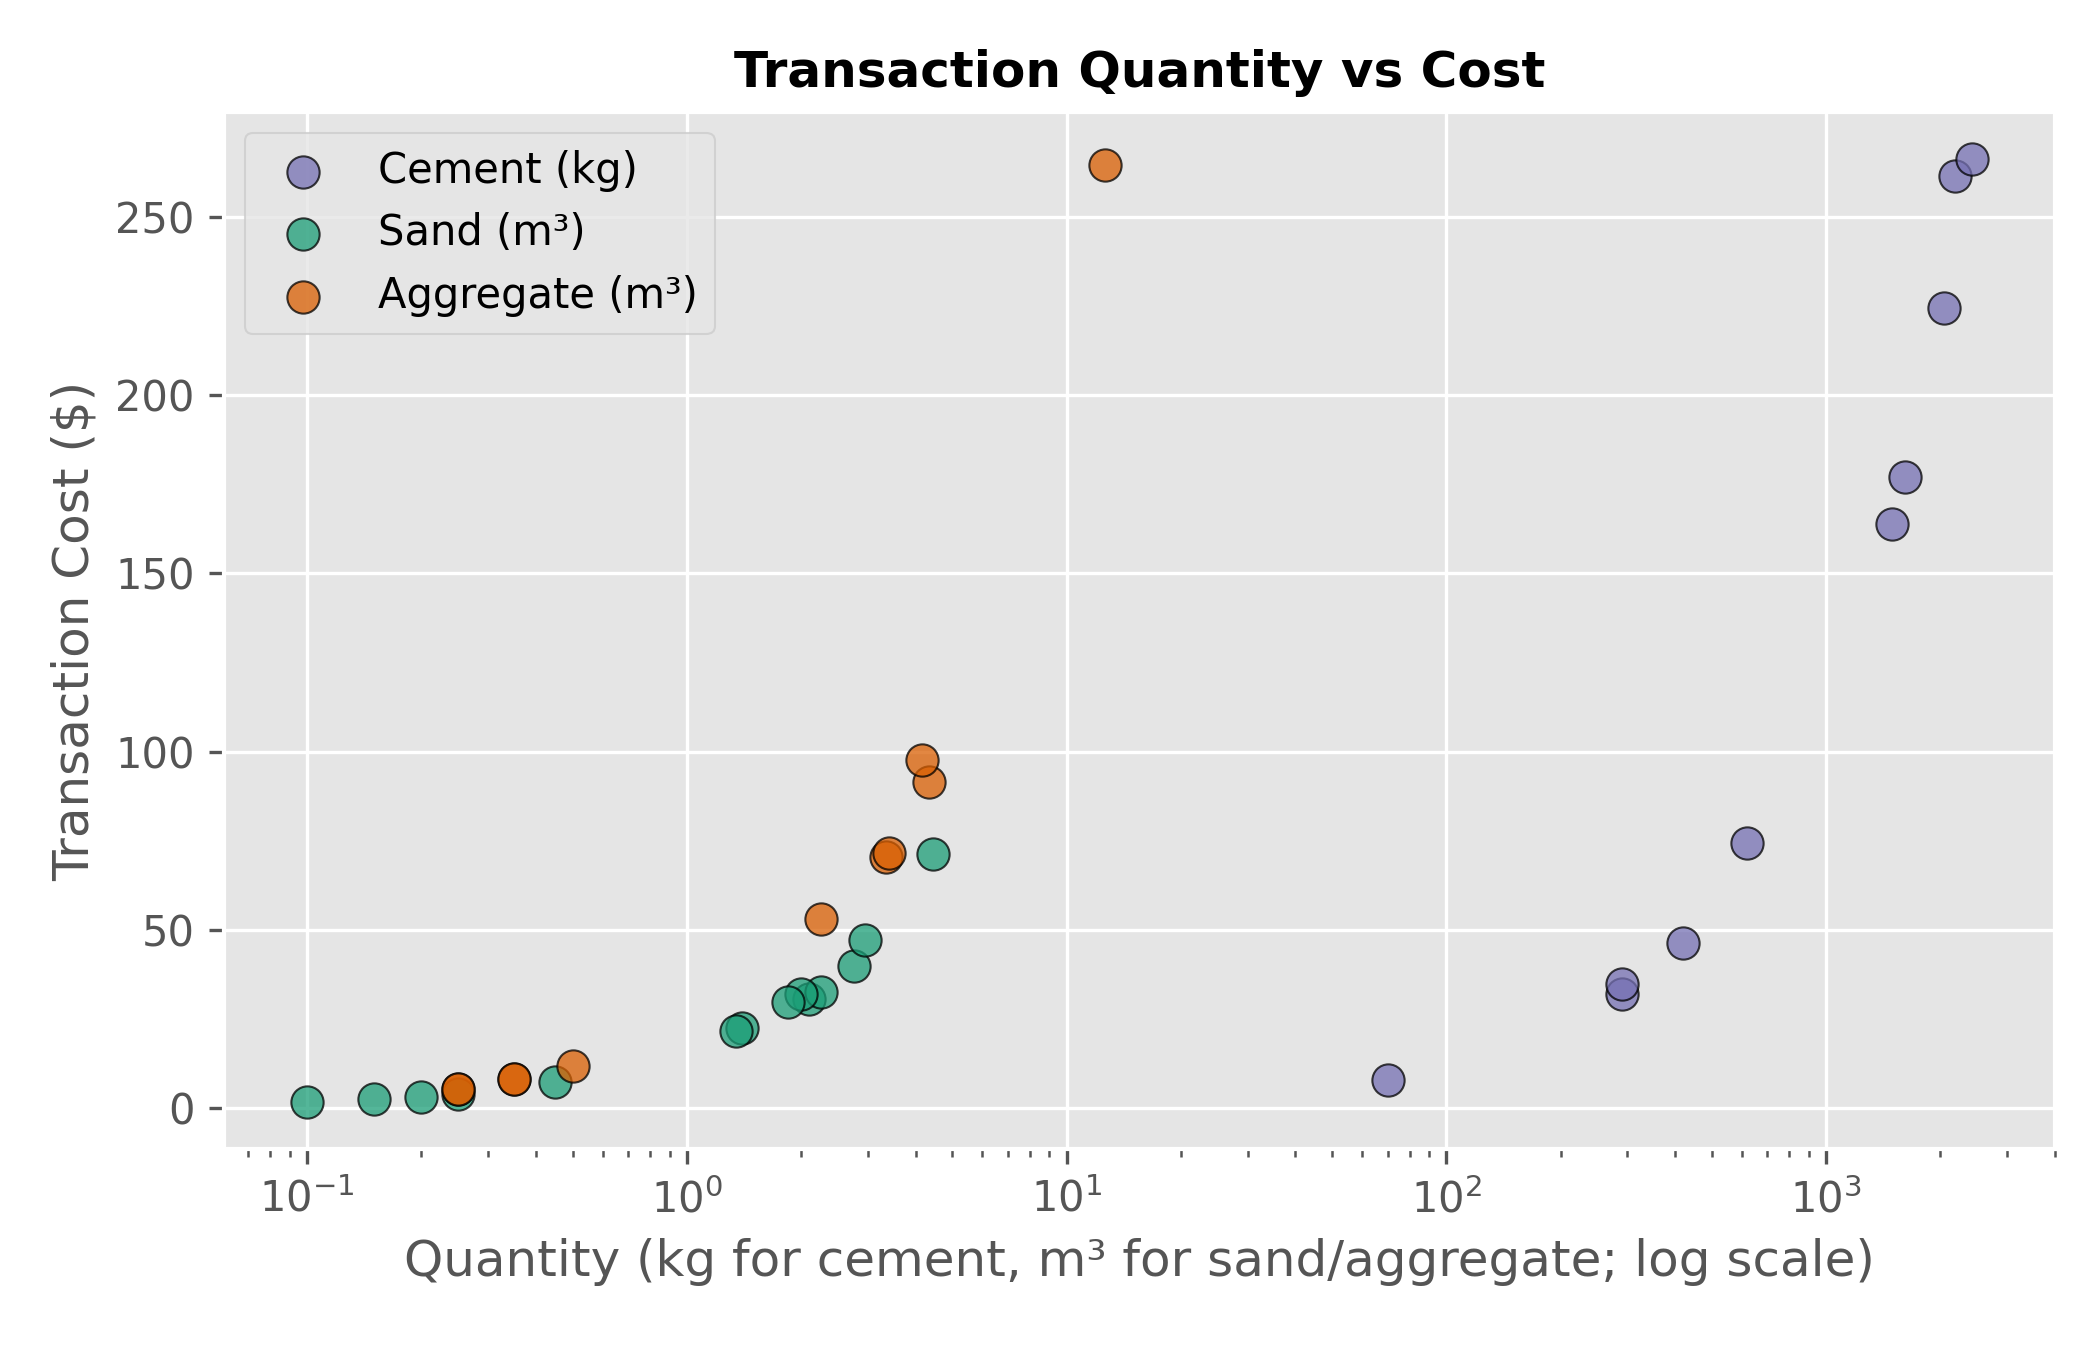

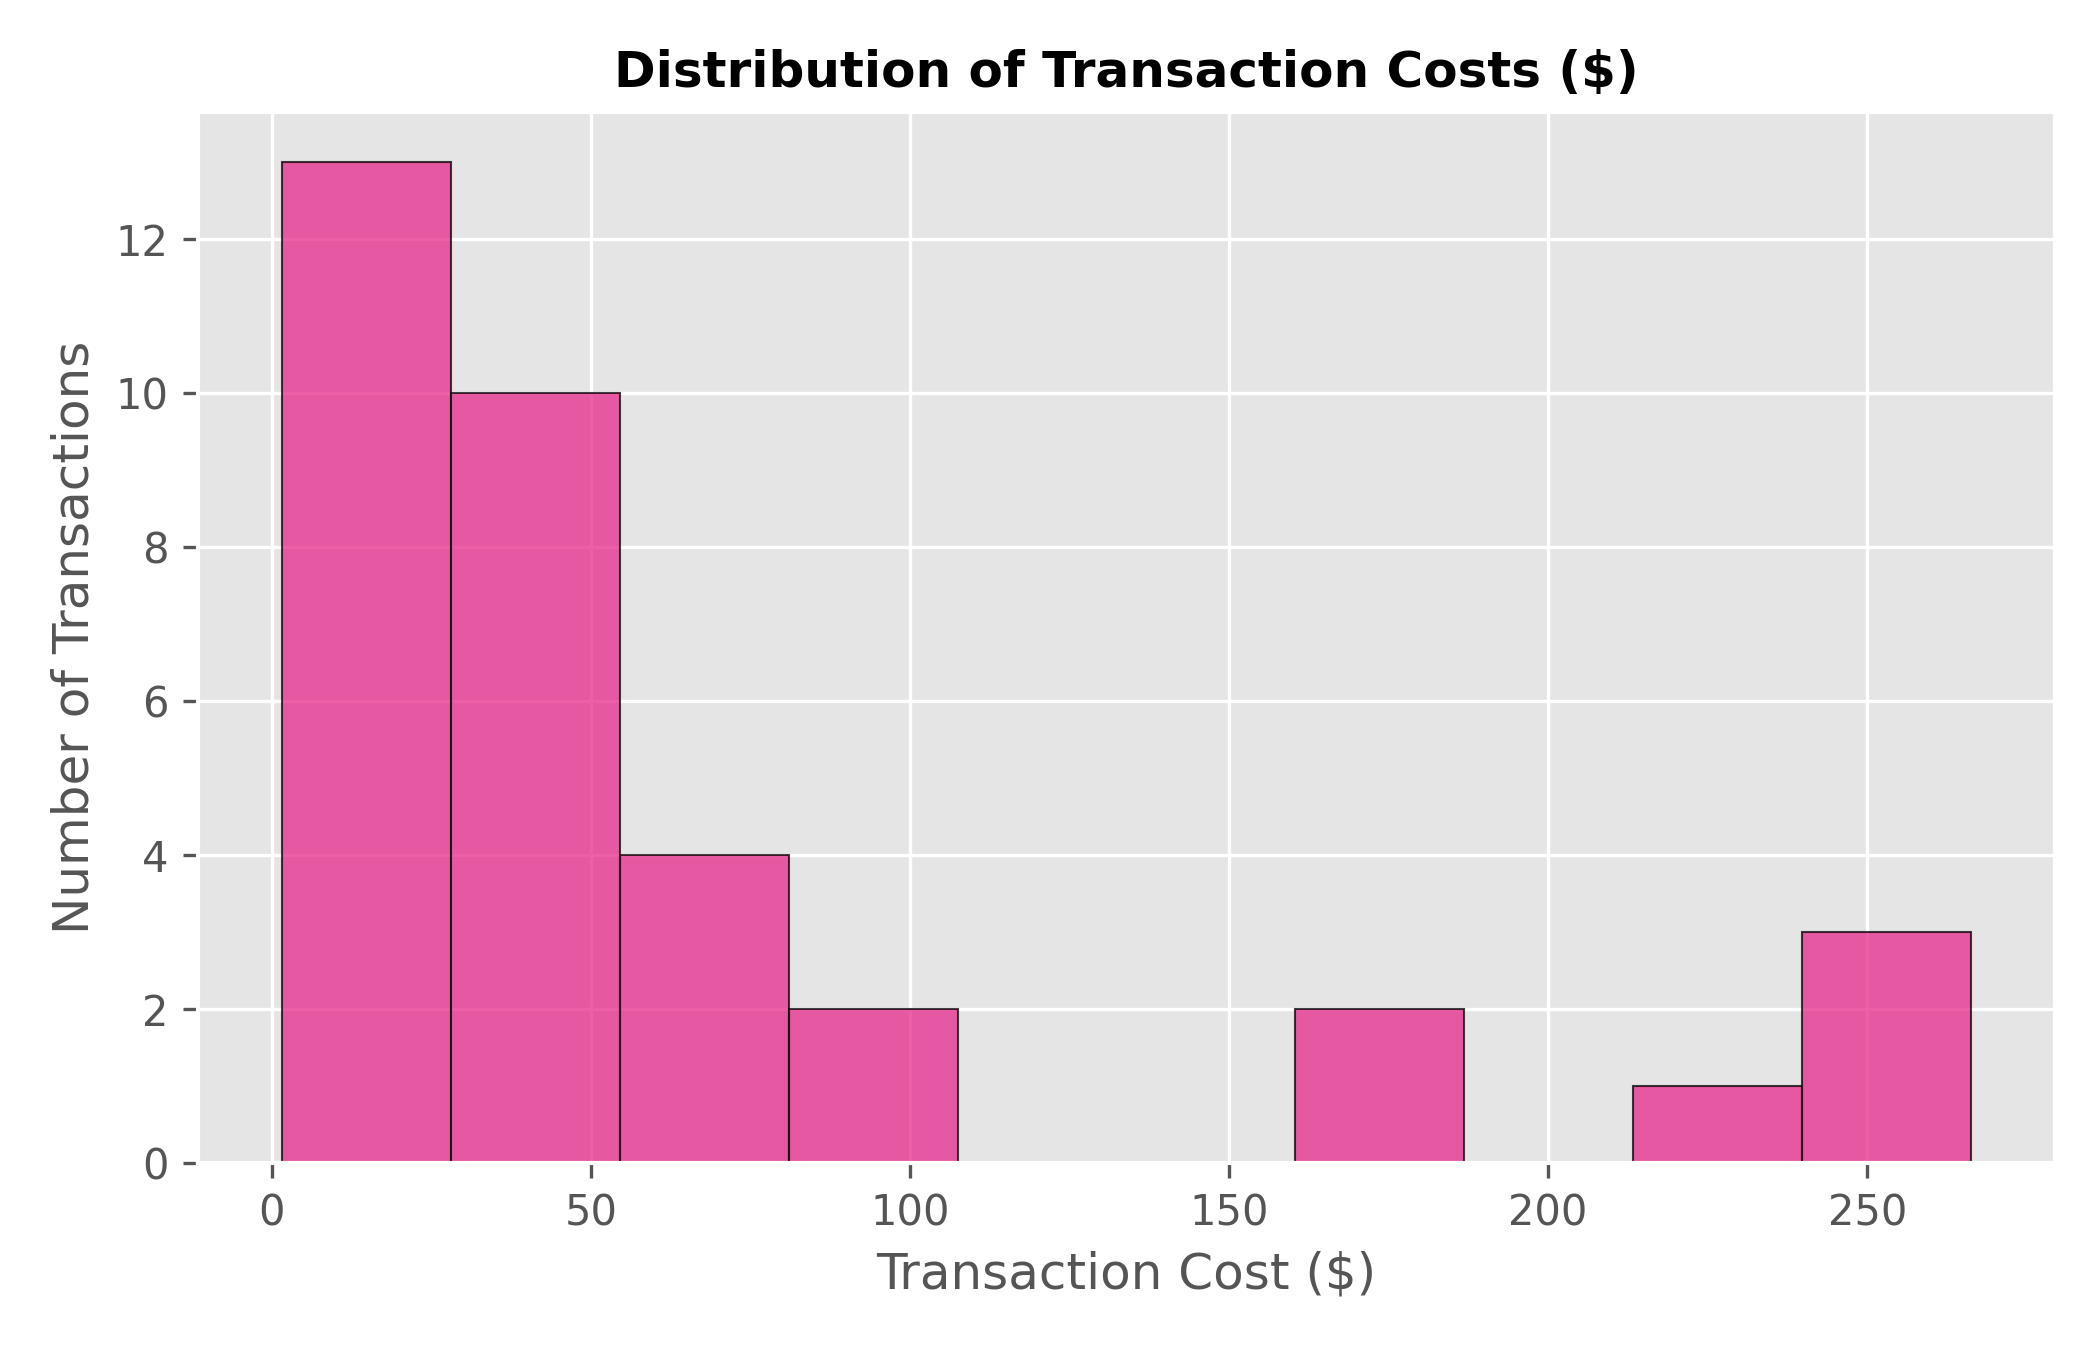

In [21]:
from IPython.display import Image, display
paths = generate_matplotlib_charts(df_merged, output_dir="outputs")
for p in paths:
    display(Image(p, width=520))

## 7. Tests (3 valid, 4 invalid)
`tests.py` records the expected and actual result of each case.

In [22]:
%run tests.py

                               case    type                                        expected                                                                    actual result
      V1 Quantities for element E01   valid             (3.75, 3.9375, 1181.25, 1.97, 3.15)                                       (3.75, 3.9375, 1181.25, 1.97, 3.15)   PASS
       V2 Cleaning sample purchases   valid                       35 clean rows, 5 rejected                                                 35 clean rows, 5 rejected   PASS
   V3 Cement +15% price sensitivity   valid                     increase = 210.65 (+/-0.50)                                                         increase = 210.65   PASS
                      I1 Length = 0 invalid                               ValueError raised ValueError: Dimensions (length, width, height) must be greater than zero.   PASS
                   I2 Waste = 150 % invalid                               ValueError raised                   ValueError: Waste percent